# PHAROS CDR: Notebook 03 - Feature Selection & Redundancy Reduction

This notebook executes systematic, multi-stage feature selection to reduce the high-dimensional feature space (998 attributes) down to a refined, non-redundant feature subset for model development.

### Selection Funnel:
1. **Constant Feature Pruning**: Discard 783 zero-variance columns.
2. **Exact Duplicate Vector Pruning**: Discard 80 duplicate feature columns.
3. **Confirmed Leakage & Pipeline Artifact Exclusion**: Exclude confirmed internal metadata attributes.
4. **Stratified Partitioning**: Maintain 80/20 train/test split to prevent selection leakage.
5. **Collinearity Reduction**: Eliminate collinear feature pairs ($|r| \ge 0.95$) prioritized by Mutual Information.
6. **Model-Based Feature Importance**: Fit an Extra Trees ensemble to compute non-linear feature importances.
7. **Rank Aggregation & Consensus Subsets**: Produce combined MI + Tree importance rankings and candidate subsets (`combined_top_50`, `consensus_41`, `top_30_mi`, `top_20_mi`).

## 1. Environment Setup & Data Ingestion
Initializing feature selection modules, setting random seeds (`RANDOM_STATE = 42`), and ingesting `dataset.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import (
    mutual_info_classif,
    SelectKBest
)

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer

from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Feature selection environment initialized.")

Feature selection environment initialized.


In [2]:
df = pd.read_csv("/content/dataset.csv")

TARGET = "label"
IDENTIFIER = "sha256"

X = df.drop(columns=[TARGET, IDENTIFIER])
y = df[TARGET].astype(int)

print("Dataset shape:", df.shape)
print("Feature matrix:", X.shape)
print("Target distribution:")
print(y.value_counts())

Dataset shape: (2330, 1000)
Feature matrix: (2330, 998)
Target distribution:
label
1    1183
0    1147
Name: count, dtype: int64


## 2. Constant Feature Removal
Dropping all feature columns where cardinality ($	ext{nunique}$) is $\le 1$ across all samples.

In [3]:
constant_features = [
    c for c in X.columns
    if X[c].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_features)

print("Removed constant features:", len(constant_features))
print("Remaining features:", X.shape[1])

Removed constant features: 783
Remaining features: 215


> [!NOTE]
> **Inference on Constant Removal**:
> **783 constant features** are removed, immediately reducing the dimensionality from 998 down to **215 variable features** with zero loss of predictive information.

## 3. Duplicate Feature Vector Removal
Identifying and removing columns that contain identical numeric vectors across all rows.

In [4]:
duplicate_features = X.columns[
    X.T.duplicated()
].tolist()

print("Duplicate features:", len(duplicate_features))

X = X.drop(columns=duplicate_features)

print("Remaining features:", X.shape[1])

Duplicate features: 80
Remaining features: 135


> [!NOTE]
> **Inference on Duplicate Removal**:
> **80 duplicate columns** are identified and discarded, reducing the remaining feature space to **135 unique features**.

## 4. Exclusion of Pipeline Artifacts & Data Leakage
Auditing and removing features that reflect internal extractor mechanics or pipeline counters rather than document attributes.

In [5]:
audit_keywords = [
    "source_size",
    "source_length",
    "pipeline_source",
    "pipeline_nonzero",
    "pipeline_total"
]

audit_features = [
    c for c in X.columns
    if any(k in c.lower() for k in audit_keywords)
]

print("Features requiring audit:", len(audit_features))

display(pd.DataFrame({
    "feature": audit_features
}))

Features requiring audit: 3


,feature
0,behavior_collection.collection_source_size
1,pipeline_nonzero_feature_count
2,pipeline_total_feature_count


In [6]:
audit_decisions = pd.DataFrame({
    "feature": audit_features,
    "decision": "REVIEW",
    "reason": ""
})

display(audit_decisions)

,feature,decision,reason
0,behavior_collection.collection_source_size,REVIEW,
1,pipeline_nonzero_feature_count,REVIEW,
2,pipeline_total_feature_count,REVIEW,


In [7]:
# Exclude pipeline metadata and suspicious source-size features.
CONFIRMED_EXCLUSIONS = [
    "behavior_collection.collection_source_size",
    "pipeline_nonzero_feature_count",
    "pipeline_total_feature_count",
]

unknown_exclusions = set(CONFIRMED_EXCLUSIONS) - set(X.columns)

assert not unknown_exclusions, (
    f"Unknown exclusion features: {unknown_exclusions}"
)

X = X.drop(columns=CONFIRMED_EXCLUSIONS)

print("Excluded features:", len(CONFIRMED_EXCLUSIONS))
print("Excluded:", CONFIRMED_EXCLUSIONS)
print("Remaining features:", X.shape[1])


Excluded features: 3
Excluded: ['behavior_collection.collection_source_size', 'pipeline_nonzero_feature_count', 'pipeline_total_feature_count']
Remaining features: 132


> [!IMPORTANT]
> **Inference on Leakage Exclusions**:
> 3 confirmed pipeline artifacts are excluded: `behavior_collection.collection_source_size`, `pipeline_nonzero_feature_count`, and `pipeline_total_feature_count`. This leaves **132 candidate features** ready for train/test partitioning.

## 5. Stratified Train / Test Partitioning
Partitioning data into 80% training ($N=1,864$) and 20% testing ($N=466$) sets. All correlation and feature ranking computations are restricted strictly to `X_train` to prevent data snooping.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 1864
Testing samples: 466

Training distribution:
label
1    0.507511
0    0.492489
Name: proportion, dtype: float64

Testing distribution:
label
1    0.508584
0    0.491416
Name: proportion, dtype: float64


## 6. Correlation Analysis & Collinearity Pruning
Computing Pearson correlation matrix and iteratively pruning highly collinear features ($|r| \ge 0.95$) guided by Mutual Information ranking.

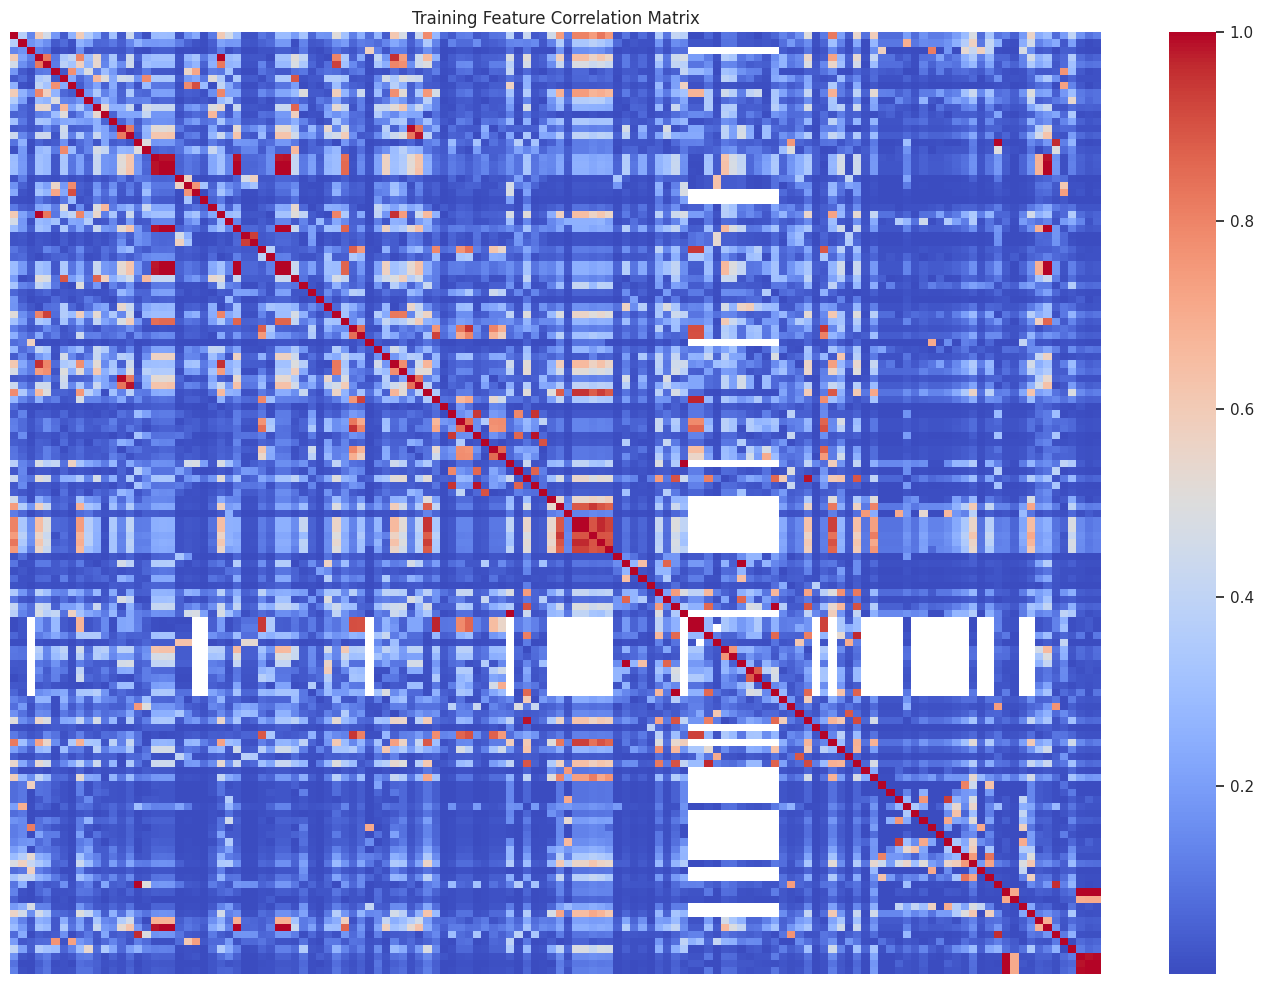

In [9]:
corr_matrix = X_train.corr(method="pearson").abs()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0.5,
    xticklabels=False,
    yticklabels=False
)

plt.title("Training Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [10]:
upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper.stack()
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

correlation_pairs = correlation_pairs[
    correlation_pairs["correlation"] >= 0.95
].sort_values(
    "correlation",
    ascending=False
)

display(correlation_pairs.head(30))

print("Highly correlated pairs:", len(correlation_pairs))

,feature_1,feature_2,correlation
400,common_entropy.entropy,common_file_features.sample_entropy,1.000000
7188,office_templates.template_total_relationships,ooxml.ooxml_relationships_total,1.000000
6863,office_templates.template_external_count,ooxml.ooxml_relationships_attached_templates,1.000000
7267,ooxml.ooxml_content_types_macro_enabled,ooxml.ooxml_content_types_macro_override_count,1.000000
6542,office_ole.ole_is_container,office_ole.ole_sector_size,1.000000
6066,office_embedded_objects.embedded_objects_packa...,office_templates.template_zip_read_error,1.000000
3853,common_metadata.metadata_path_directory_length,script_powershell.powershell_base64_token_count,1.000000
3158,common_metadata.metadata_created_modified_delta,common_metadata.metadata_path_directory_length,0.999966
3250,common_metadata.metadata_created_modified_delta,script_powershell.powershell_base64_token_count,0.999966
2194,common_file_features.filename_length,common_file_features.filename_stem_length,0.999891


Highly correlated pairs: 51


In [11]:
X_train_filled = X_train.fillna(
    X_train.median()
)

mi_scores = mutual_info_classif(
    X_train_filled,
    y_train,
    discrete_features=[
        X_train_filled[c].nunique() <= 10
        for c in X_train_filled.columns
    ],
    random_state=RANDOM_STATE
)

mi_ranking = pd.Series(
    mi_scores,
    index=X_train.columns
).sort_values(ascending=False)

selected = []
removed_correlated = set()

for feature in mi_ranking.index:

    if feature in removed_correlated:
        continue

    selected.append(feature)

    correlated = corr_matrix[feature][
        corr_matrix[feature] >= 0.95
    ].index.tolist()

    removed_correlated.update(
        c for c in correlated
        if c != feature
    )

correlation_selected_features = selected

print("Before correlation reduction:", X_train.shape[1])
print("After correlation reduction:", len(selected))
print("Removed:", X_train.shape[1] - len(selected))

Before correlation reduction: 132
After correlation reduction: 105
Removed: 27


> [!TIP]
> **Inference on Collinearity Reduction**:
> Greedy correlation reduction eliminated **27 redundant collinear features**, yielding **exactly 105 uncorrelated, informative features**.

## 7. Model-Based Feature Importance (Extra Trees)
Fitting an `ExtraTreesClassifier(n_estimators=300, class_weight='balanced')` on the 105 features to derive tree-based Gini importances.

In [12]:
X_corr = X_train[correlation_selected_features]

imputer = SimpleImputer(strategy="median")

X_corr_filled = pd.DataFrame(
    imputer.fit_transform(X_corr),
    columns=X_corr.columns,
    index=X_corr.index
)

discrete_mask = [
    X_corr_filled[c].nunique() <= 10
    for c in X_corr_filled.columns
]

mi_scores = mutual_info_classif(
    X_corr_filled,
    y_train,
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE
)

mi_results = pd.DataFrame({
    "feature": X_corr.columns,
    "mutual_information": mi_scores
}).sort_values(
    "mutual_information",
    ascending=False
)

display(mi_results.head(30))

,feature,mutual_information
0,common_metadata.metadata_created_modified_delta,0.693303
1,common_metadata.metadata_filename_entropy,0.624881
2,ooxml.ooxml_document_text_characters,0.621780
3,ooxml.ooxml_document_paragraphs,0.581213
4,ooxml.zip_compression_ratio,0.553353
5,ooxml.zip_uncompressed_size,0.541700
6,ooxml.zip_suspicious_parts,0.520861
7,ooxml.zip_xml_parts,0.451788
8,derived.large_compression_ratio_indicator,0.449879
9,ooxml.zip_compressed_size,0.449138


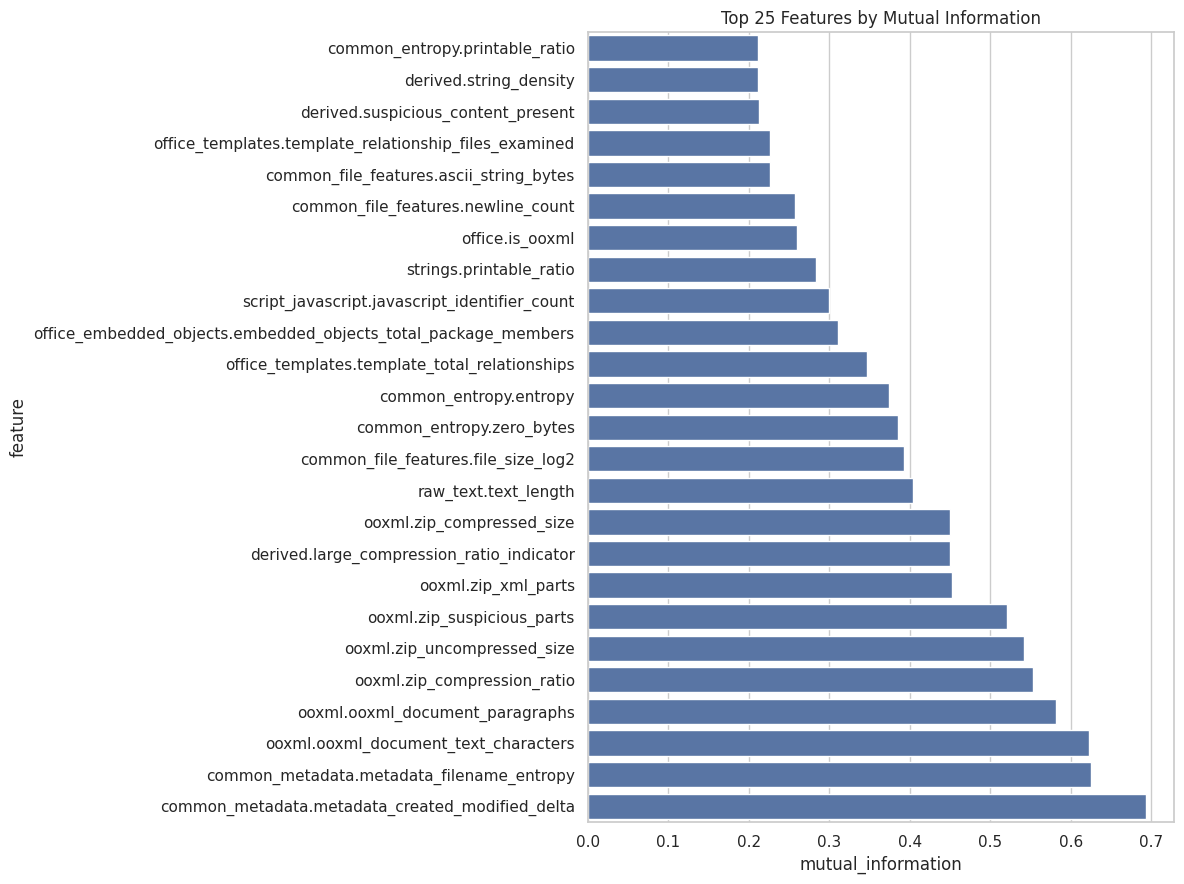

In [13]:
top_mi = mi_results.head(25).sort_values(
    "mutual_information"
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_mi,
    x="mutual_information",
    y="feature"
)

plt.title("Top 25 Features by Mutual Information")
plt.tight_layout()
plt.show()

In [14]:
K_VALUES = [20, 30, 50, 75, 100]

statistical_subsets = {}

for k in K_VALUES:

    actual_k = min(k, len(mi_results))

    statistical_subsets[k] = (
        mi_results.head(actual_k)["feature"].tolist()
    )

    print(
        f"Top {actual_k} features selected: "
        f"{len(statistical_subsets[k])}"
    )

Top 20 features selected: 20
Top 30 features selected: 30
Top 50 features selected: 50
Top 75 features selected: 75
Top 100 features selected: 100


In [15]:
extra_trees = ExtraTreesClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1
)

extra_trees.fit(
    X_corr_filled,
    y_train
)

importance_results = pd.DataFrame({
    "feature": X_corr.columns,
    "importance": extra_trees.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(importance_results.head(30))

,feature,importance
0,common_metadata.metadata_created_modified_delta,0.242717
8,derived.large_compression_ratio_indicator,0.156826
16,script_javascript.javascript_identifier_count,0.114629
19,office.is_ooxml,0.064956
22,derived.suspicious_content_present,0.052690
28,file.extension_known,0.043613
6,ooxml.zip_suspicious_parts,0.040623
2,ooxml.ooxml_document_text_characters,0.029118
3,ooxml.ooxml_document_paragraphs,0.027717
7,ooxml.zip_xml_parts,0.017383


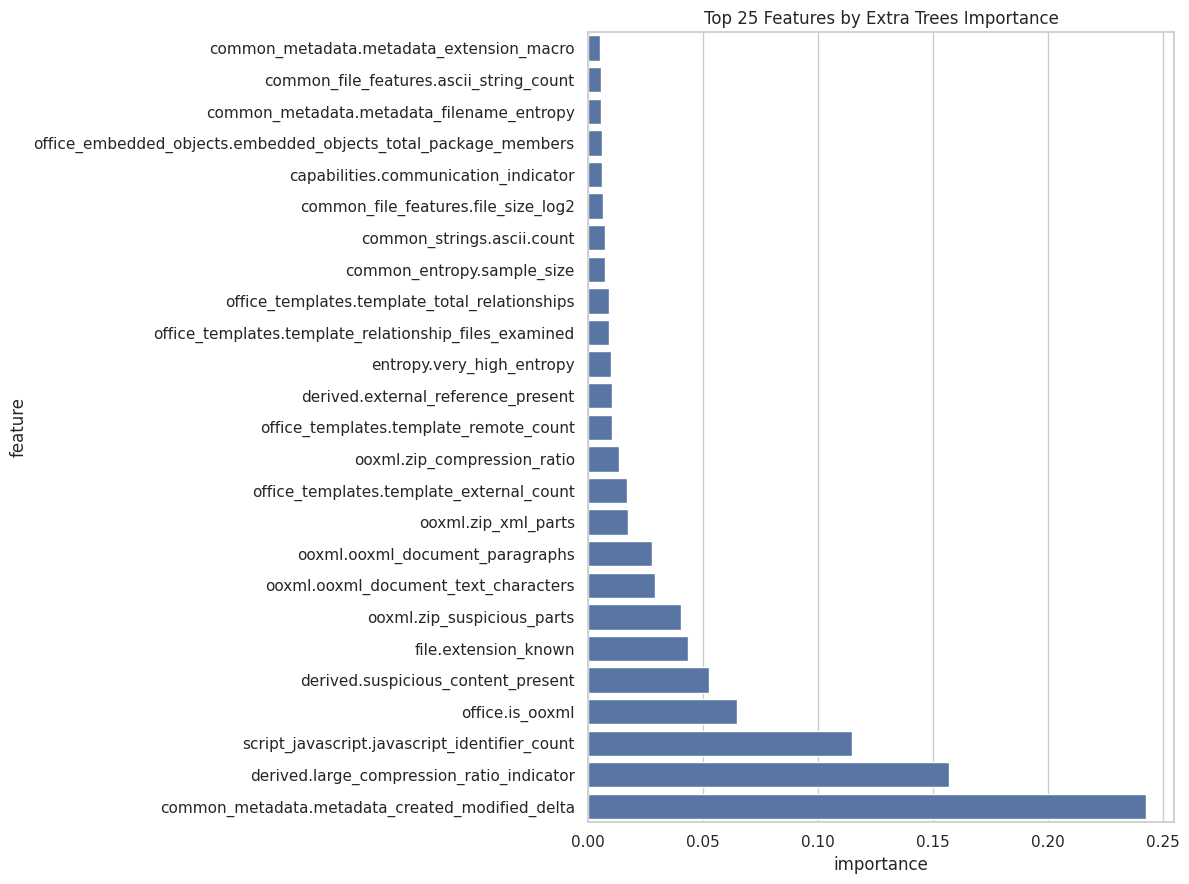

In [16]:
top_importance = importance_results.head(25).sort_values(
    "importance"
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_importance,
    x="importance",
    y="feature"
)

plt.title("Top 25 Features by Extra Trees Importance")
plt.tight_layout()
plt.show()

## 8. Rank Aggregation & Consensus Feature Subsets
Computing average rank across Mutual Information and Extra Trees importance to identify the most robust feature subsets.

In [17]:
ranking_comparison = mi_results.merge(
    importance_results,
    on="feature"
)

ranking_comparison["mi_rank"] = (
    ranking_comparison["mutual_information"]
    .rank(ascending=False)
)

ranking_comparison["importance_rank"] = (
    ranking_comparison["importance"]
    .rank(ascending=False)
)

ranking_comparison["average_rank"] = (
    ranking_comparison["mi_rank"]
    + ranking_comparison["importance_rank"]
) / 2

ranking_comparison = ranking_comparison.sort_values(
    "average_rank"
)

display(ranking_comparison.head(30))

,feature,mutual_information,importance,mi_rank,importance_rank,average_rank
0,common_metadata.metadata_created_modified_delta,0.693303,0.242717,1.0,1.0,1.0
2,ooxml.ooxml_document_text_characters,0.621780,0.029118,3.0,8.0,5.5
8,derived.large_compression_ratio_indicator,0.449879,0.156826,9.0,2.0,5.5
3,ooxml.ooxml_document_paragraphs,0.581213,0.027717,4.0,9.0,6.5
6,ooxml.zip_suspicious_parts,0.520861,0.040623,7.0,7.0,7.0
4,ooxml.zip_compression_ratio,0.553353,0.013321,5.0,12.0,8.5
7,ooxml.zip_xml_parts,0.451788,0.017383,8.0,10.0,9.0
16,script_javascript.javascript_identifier_count,0.299918,0.114629,17.0,3.0,10.0
18,office.is_ooxml,0.259033,0.064956,19.0,4.0,11.5
1,common_metadata.metadata_filename_entropy,0.624881,0.005516,2.0,23.0,12.5


In [18]:
top_mi_features = set(
    mi_results.head(50)["feature"]
)

top_tree_features = set(
    importance_results.head(50)["feature"]
)

consensus_features = (
    top_mi_features & top_tree_features
)

print("Top MI features:", len(top_mi_features))
print("Top Extra Trees features:", len(top_tree_features))
print("Common features:", len(consensus_features))

display(
    ranking_comparison[
        ranking_comparison["feature"].isin(consensus_features)
    ].sort_values("average_rank")
)

Top MI features: 50
Top Extra Trees features: 50
Common features: 41


,feature,mutual_information,importance,mi_rank,importance_rank,average_rank
0,common_metadata.metadata_created_modified_delta,0.693303,0.242717,1.0,1.0,1.00
2,ooxml.ooxml_document_text_characters,0.621780,0.029118,3.0,8.0,5.50
8,derived.large_compression_ratio_indicator,0.449879,0.156826,9.0,2.0,5.50
3,ooxml.ooxml_document_paragraphs,0.581213,0.027717,4.0,9.0,6.50
6,ooxml.zip_suspicious_parts,0.520861,0.040623,7.0,7.0,7.00
4,ooxml.zip_compression_ratio,0.553353,0.013321,5.0,12.0,8.50
7,ooxml.zip_xml_parts,0.451788,0.017383,8.0,10.0,9.00
16,script_javascript.javascript_identifier_count,0.299918,0.114629,17.0,3.0,10.00
18,office.is_ooxml,0.259033,0.064956,19.0,4.0,11.50
1,common_metadata.metadata_filename_entropy,0.624881,0.005516,2.0,23.0,12.50


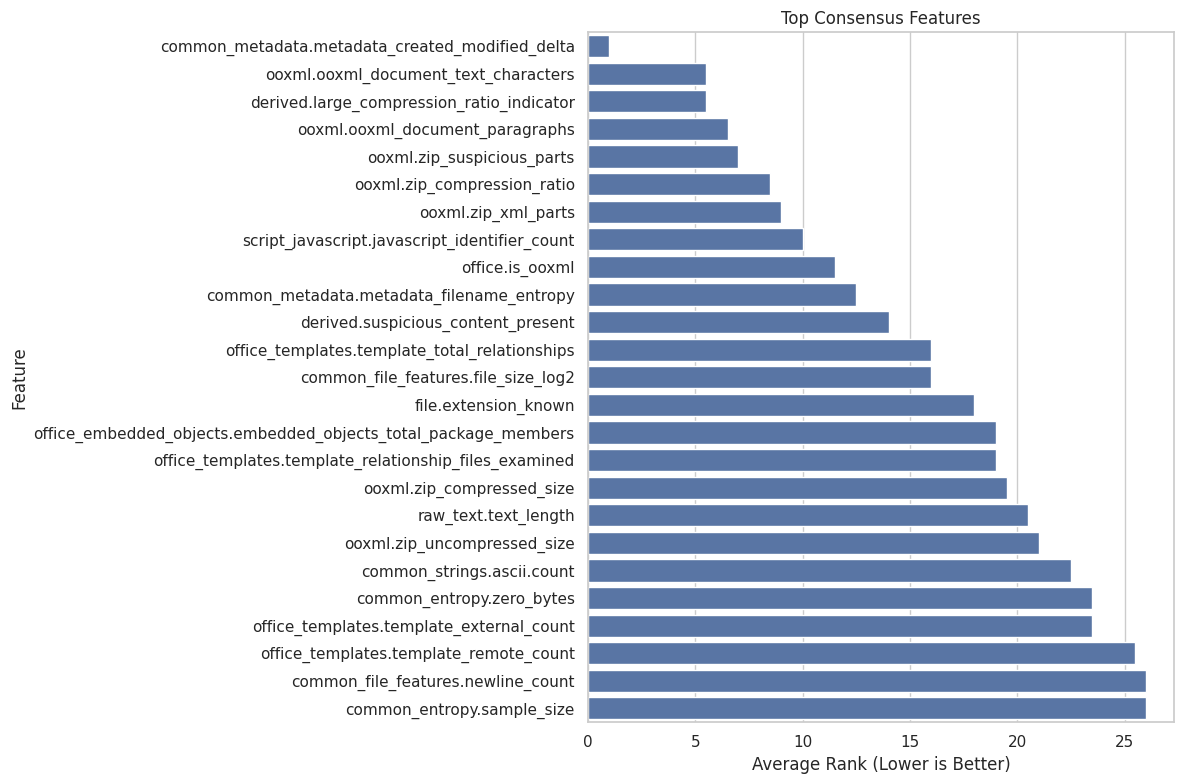

In [19]:
consensus_df = ranking_comparison[
    ranking_comparison["feature"].isin(consensus_features)
].sort_values("average_rank").head(25)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=consensus_df,
    x="average_rank",
    y="feature"
)

plt.title("Top Consensus Features")
plt.xlabel("Average Rank (Lower is Better)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [20]:
FINAL_K = 50

ranked_features = ranking_comparison[
    "feature"
].tolist()

consensus_ranked = ranking_comparison[
    ranking_comparison["feature"].isin(consensus_features)
]["feature"].tolist()

feature_subsets = {
    "top_20_mi": statistical_subsets[20],
    "top_30_mi": statistical_subsets[30],
    "top_50_mi": statistical_subsets[50],
    "top_75_mi": statistical_subsets[75],
    "top_100_mi": statistical_subsets[100],
    "extra_trees_top_50": importance_results.head(50)["feature"].tolist(),
    "consensus": consensus_ranked,
    "combined_top_50": ranked_features[:FINAL_K]
}

for name, features in feature_subsets.items():
    print(f"{name}: {len(features)} features")

top_20_mi: 20 features
top_30_mi: 30 features
top_50_mi: 50 features
top_75_mi: 75 features
top_100_mi: 100 features
extra_trees_top_50: 50 features
consensus: 41 features
combined_top_50: 50 features


> [!NOTE]
> **Inference on Consensus Subsets**:
> - **41 features** appear unanimously in the Top 50 of both Mutual Information and Extra Trees importance (`consensus.csv`).
> - The combined ranking (`combined_feature_ranking.csv`) provides a deterministic hierarchy for evaluating compact feature sets.

## 9. Serialization & Export of Selection Artifacts
Exporting all feature rankings, correlation tables, and candidate subsets to `notebooks/feature_selection/`.

In [21]:
output_dir = Path("/content/feature_selection")
output_dir.mkdir(exist_ok=True)

# Export statistical rankings
mi_results.to_csv(
    output_dir / "mutual_information_ranking.csv",
    index=False
)

# Export model-based rankings
importance_results.to_csv(
    output_dir / "extra_trees_ranking.csv",
    index=False
)

# Export combined ranking
ranking_comparison.to_csv(
    output_dir / "combined_feature_ranking.csv",
    index=False
)

# Export correlated feature pairs
correlation_pairs.to_csv(
    output_dir / "correlated_features.csv",
    index=False
)

# Export selected feature subsets
for name, features in feature_subsets.items():

    pd.DataFrame({
        "feature": features
    }).to_csv(
        output_dir / f"{name}.csv",
        index=False
    )

# Export confirmed exclusions
pd.DataFrame({
    "feature": CONFIRMED_EXCLUSIONS
}).to_csv(
    output_dir / "excluded_features.csv",
    index=False
)

print("Feature selection results exported successfully.")

Feature selection results exported successfully.


In [22]:
print("=" * 60)
print("CDR FEATURE SELECTION REPORT")
print("=" * 60)

print("Original feature count:", df.shape[1] - 2)
print("Constant features removed:", len(constant_features))
print("Duplicate features removed:", len(duplicate_features))
print("Confirmed exclusions:", len(CONFIRMED_EXCLUSIONS))

print("Remaining after cleanup:", X.shape[1])
print("After correlation reduction:", len(correlation_selected_features))

print("\nFEATURE SUBSETS")

for name, features in feature_subsets.items():
    print(f"{name}: {len(features)}")

print("\nTOP 15 CONSENSUS FEATURES")

display(
    ranking_comparison.head(15)[
        [
            "feature",
            "mutual_information",
            "importance",
            "average_rank"
        ]
    ]
)

print("=" * 60)

CDR FEATURE SELECTION REPORT
Original feature count: 998
Constant features removed: 783
Duplicate features removed: 80
Confirmed exclusions: 3
Remaining after cleanup: 132
After correlation reduction: 105

FEATURE SUBSETS
top_20_mi: 20
top_30_mi: 30
top_50_mi: 50
top_75_mi: 75
top_100_mi: 100
extra_trees_top_50: 50
consensus: 41
combined_top_50: 50

TOP 15 CONSENSUS FEATURES


,feature,mutual_information,importance,average_rank
0,common_metadata.metadata_created_modified_delta,0.693303,0.242717,1.0
2,ooxml.ooxml_document_text_characters,0.621780,0.029118,5.5
8,derived.large_compression_ratio_indicator,0.449879,0.156826,5.5
3,ooxml.ooxml_document_paragraphs,0.581213,0.027717,6.5
6,ooxml.zip_suspicious_parts,0.520861,0.040623,7.0
4,ooxml.zip_compression_ratio,0.553353,0.013321,8.5
7,ooxml.zip_xml_parts,0.451788,0.017383,9.0
16,script_javascript.javascript_identifier_count,0.299918,0.114629,10.0
18,office.is_ooxml,0.259033,0.064956,11.5
1,common_metadata.metadata_filename_entropy,0.624881,0.005516,12.5


> [!IMPORTANT]
> **Key Takeaway & Transition to Notebook 04**:
> - Multi-stage selection compressed 998 raw features down to **105 informative features** (and 41 consensus features).
> - All subsets are exported to `notebooks/feature_selection/`.
> - Notebook 04 will evaluate these 105 features, conduct a deeper leakage audit to remove single-feature shortcuts, and train production-ready classifiers.